# 03 - Uji A/B Kampanye Musim Puncak: Periode A (Q4 2010) vs Periode B (Q4 2011)

## Konteks dan kejujuran metodologis

Dataset Online Retail II **tidak memuat eksperimen terkontrol** (tidak ada kolom yang menandai pelanggan mana yang menerima promosi). Karena itu notebook ini menerapkan **kerangka uji A/B pada kuasi-eksperimen**: dua periode kampanye musim puncak yang sebanding diperlakukan sebagai kelompok A dan B.

| Kelompok | Periode | Keterangan |
|---|---|---|
| **A** | 1 Okt - 9 Des 2010 | Musim puncak tahun pertama |
| **B** | 1 Okt - 9 Des 2011 | Musim puncak tahun kedua (jendela disamakan karena data berakhir 9 Des 2011) |

Pertanyaan bisnisnya: **apakah performa musim puncak 2011 berbeda secara bermakna dari 2010?** Diukur dengan tiga metrik:

1. **Rata-rata nilai keranjang per invoice** (metrik utama) - uji t Welch, interval kepercayaan 95%, Cohen's d, dan bootstrap sebagai pembanding nonparametrik.
2. **Tingkat pembelian ulang** - proporsi pelanggan terdaftar yang belanja >= 2 kali dalam periode - uji chi-square.
3. **Tingkat retur** - proporsi pelanggan terdaftar yang melakukan >= 1 retur dalam periode - uji chi-square.

Hipotesis untuk setiap metrik: H0: metrik A = metrik B; H1: metrik A != metrik B (dua sisi), alpha = 0,05.

**Keterbatasan yang harus diingat saat membaca hasil**: tidak ada randomisasi, sehingga perbedaan yang ditemukan bisa disebabkan faktor lain (pertumbuhan basis pelanggan, inflasi, perubahan katalog). Notebook ini menunjukkan *cara* menganalisis uji A/B secara benar; dalam eksperimen sungguhan, kelompok harus diacak sebelum kampanye dimulai. Fungsi statistik ada di `src/analysis/ab_test.py` dan diuji di `tests/test_ab_test.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.power import TTestIndPower

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.analysis.ab_test import bootstrap_mean_diff, interpret_effect_size, interpret_p, proportion_test, welch_ttest  # noqa: E402
from src.config import ASSETS_DIR, CLEAN_PARQUET  # noqa: E402
from src.data.clean import RETURNS_PARQUET  # noqa: E402
from src.viz import GROUP_COLORS, INK_MUTED, INK_SECONDARY, apply_matplotlib_style  # noqa: E402

apply_matplotlib_style()
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sales = pd.read_parquet(CLEAN_PARQUET)
returns = pd.read_parquet(RETURNS_PARQUET)

PERIODS = {
    "A": (pd.Timestamp("2010-10-01"), pd.Timestamp("2010-12-09 23:59:59")),
    "B": (pd.Timestamp("2011-10-01"), pd.Timestamp("2011-12-09 23:59:59")),
}


def assign_group(df: pd.DataFrame) -> pd.Series:
    group = pd.Series(pd.NA, index=df.index, dtype="string")
    for name, (start, end) in PERIODS.items():
        group[df["invoice_date"].between(start, end)] = name
    return group


sales["group"] = assign_group(sales)
returns["group"] = assign_group(returns)
sales_ab = sales.dropna(subset=["group"])
returns_ab = returns.dropna(subset=["group"])
print(sales_ab.groupby("group").agg(rows=("invoice_no", "size"), invoices=("invoice_no", "nunique"), customers=("customer_id", "nunique"), revenue=("line_total", "sum")))

         rows  invoices  customers       revenue
group                                           
A      153066      5793       2579 2,931,899.950
B      164783      5572       2559 3,169,911.280


## 1. Membangun tabel per invoice (unit analisis)

Unit analisis metrik utama adalah **invoice**, bukan baris item, karena nilai keranjang didefinisikan per pesanan. Setiap invoice dirangkum menjadi nilai total, jumlah unit, dan jumlah lini produk.

In [2]:
basket = sales_ab.groupby(["group", "invoice_no"]).agg(value=("line_total", "sum"), units=("quantity", "sum"), lines=("stock_code", "nunique"), customer_id=("customer_id", "first"), is_guest=("is_guest", "first")).reset_index()
summary = basket.groupby("group")["value"].agg(["count", "mean", "median", "std", lambda s: s.quantile(0.9)]).rename(columns={"<lambda_0>": "p90"})
display(summary)
A = basket.loc[basket["group"] == "A", "value"].to_numpy()
B = basket.loc[basket["group"] == "B", "value"].to_numpy()

,count,mean,median,std,p90
group,,,,,
A,5793,506.111,300.660,"1,318.295",886.794
B,5572,568.900,302.935,"2,647.784",928.048


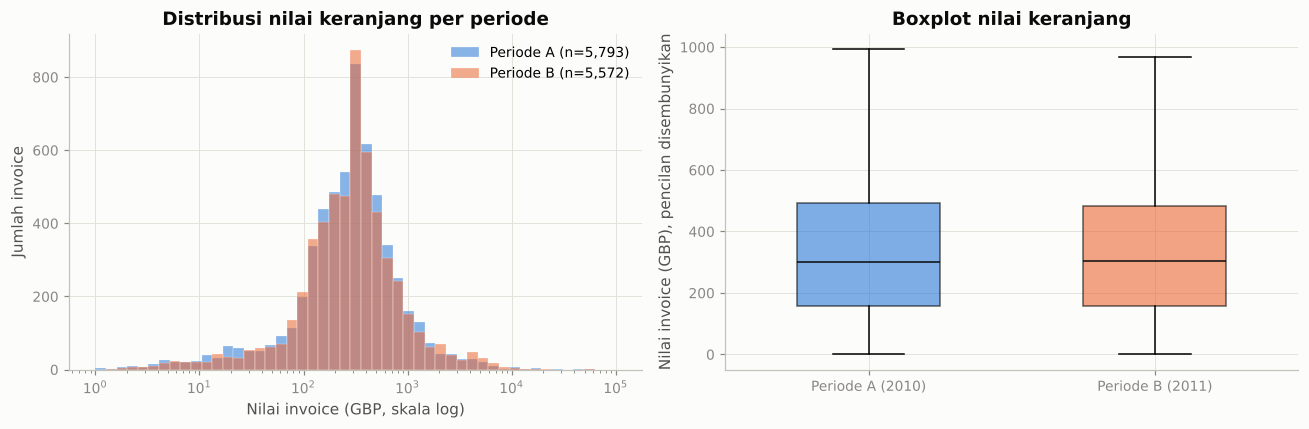

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(0, 5, 50)
for name, values in [("A", A), ("B", B)]:
    axes[0].hist(values, bins=bins, alpha=0.55, color=GROUP_COLORS[name], edgecolor="white", linewidth=0.3, label=f"Periode {name} (n={len(values):,})")
axes[0].set_xscale("log")
axes[0].set_xlabel("Nilai invoice (GBP, skala log)")
axes[0].set_ylabel("Jumlah invoice")
axes[0].set_title("Distribusi nilai keranjang per periode")
axes[0].legend()
box = axes[1].boxplot([A, B], tick_labels=["Periode A (2010)", "Periode B (2011)"], showfliers=False, patch_artist=True, widths=0.5)
for patch, name in zip(box["boxes"], ["A", "B"]):
    patch.set_facecolor(GROUP_COLORS[name])
    patch.set_alpha(0.6)
for median in box["medians"]:
    median.set_color("#0b0b0b")
axes[1].set_ylabel("Nilai invoice (GBP), pencilan disembunyikan")
axes[1].set_title("Boxplot nilai keranjang")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "ab_distribusi_keranjang.png")
plt.show()

## 2. Metrik utama: rata-rata nilai keranjang (uji t Welch)

Uji t Welch dipilih karena tidak mengasumsikan varians kedua kelompok sama. Dengan ribuan invoice per kelompok, teorema limit pusat membuat uji t tetap sahih meski distribusinya miring; sebagai pengaman, interval kepercayaan bootstrap dan uji pada skala log ditampilkan juga.

In [4]:
res = welch_ttest(A, B)
boot_low, boot_high = bootstrap_mean_diff(A, B, n_boot=5000, seed=42)
res_log = welch_ttest(np.log(A), np.log(B))

print(f"Rata-rata A : GBP {res.mean_a:,.2f}  (n = {res.n_a:,})")
print(f"Rata-rata B : GBP {res.mean_b:,.2f}  (n = {res.n_b:,})")
print(f"Selisih B-A : GBP {res.diff:,.2f}  ({res.relative_lift:+.1%})")
print(f"IK 95% Welch: [GBP {res.ci_low:,.2f}, GBP {res.ci_high:,.2f}]")
print(f"IK 95% bootstrap: [GBP {boot_low:,.2f}, GBP {boot_high:,.2f}]")
print(f"t = {res.t_stat:.3f}, df = {res.df:,.1f}, p = {res.p_value:.4f} -> {interpret_p(res.p_value)}")
print(f"Cohen's d = {res.cohens_d:.3f} -> ukuran efek {interpret_effect_size(res.cohens_d)}")
print()
print(f"Robustness (skala log): rasio geometrik B/A = {np.exp(res_log.diff):.3f}, p = {res_log.p_value:.4f}")

Rata-rata A : GBP 506.11  (n = 5,793)
Rata-rata B : GBP 568.90  (n = 5,572)
Selisih B-A : GBP 62.79  (+12.4%)
IK 95% Welch: [GBP -14.59, GBP 140.17]
IK 95% bootstrap: [GBP -5.46, GBP 150.74]
t = 1.591, df = 8,101.3, p = 0.1117 -> tidak signifikan secara statistik (p = 0.1117 >= 0.05)
Cohen's d = 0.030 -> ukuran efek dapat diabaikan

Robustness (skala log): rasio geometrik B/A = 1.054, p = 0.0204


## 3. Metrik proporsi: pembelian ulang dan retur (chi-square)

Kedua metrik dihitung per **pelanggan terdaftar** (tamu tidak bisa dilacak lintas invoice).

- *Pembelian ulang*: pelanggan dengan >= 2 invoice penjualan dalam periode.
- *Retur*: pelanggan dengan >= 1 invoice retur dalam periode.

In [5]:
cust = basket[~basket["is_guest"]].groupby(["group", "customer_id"]).agg(invoices=("invoice_no", "nunique")).reset_index()
cust["repeat"] = cust["invoices"] >= 2
ret_cust = returns_ab.dropna(subset=["customer_id"]).groupby("group")["customer_id"].apply(set)
cust["returned"] = [cid in ret_cust.get(g, set()) for g, cid in zip(cust["group"], cust["customer_id"])]

rates = cust.groupby("group").agg(customers=("customer_id", "size"), repeat_customers=("repeat", "sum"), return_customers=("returned", "sum"))
rates["repeat_rate"] = rates["repeat_customers"] / rates["customers"]
rates["return_rate"] = rates["return_customers"] / rates["customers"]
display(rates)

rep = proportion_test(int(rates.loc["A", "repeat_customers"]), int(rates.loc["A", "customers"]), int(rates.loc["B", "repeat_customers"]), int(rates.loc["B", "customers"]))
ret = proportion_test(int(rates.loc["A", "return_customers"]), int(rates.loc["A", "customers"]), int(rates.loc["B", "return_customers"]), int(rates.loc["B", "customers"]))
for label, r in [("Tingkat pembelian ulang", rep), ("Tingkat retur", ret)]:
    print(f"{label}: A = {r.rate_a:.1%}, B = {r.rate_b:.1%}, selisih = {r.diff:+.1%} poin (IK 95% [{r.ci_low:+.1%}, {r.ci_high:+.1%}]), chi2 = {r.chi2:.2f}, p = {r.p_value:.4f} -> {interpret_p(r.p_value)}")

,customers,repeat_customers,return_customers,repeat_rate,return_rate
group,,,,,
A,2579,1150,670,0.446,0.260
B,2559,1112,569,0.435,0.222


Tingkat pembelian ulang: A = 44.6%, B = 43.5%, selisih = -1.1% poin (IK 95% [-3.9%, +1.6%]), chi2 = 0.67, p = 0.4119 -> tidak signifikan secara statistik (p = 0.4119 >= 0.05)
Tingkat retur: A = 26.0%, B = 22.2%, selisih = -3.7% poin (IK 95% [-6.1%, -1.4%]), chi2 = 9.84, p = 0.0017 -> signifikan secara statistik (p = 0.0017 < 0.05)


## 4. Uji A/A sebagai pemeriksaan kewarasan

Jika invoice periode A dibagi dua secara acak, uji yang sama seharusnya **tidak** menemukan perbedaan (p > 0,05). Ini memastikan prosedur uji tidak menghasilkan positif palsu karena kesalahan implementasi.

In [6]:
rng = np.random.default_rng(2024)
mask = rng.random(len(A)) < 0.5
aa = welch_ttest(A[mask], A[~mask])
print(f"Uji A/A: rata-rata {aa.mean_a:,.2f} vs {aa.mean_b:,.2f}, p = {aa.p_value:.4f} -> {interpret_p(aa.p_value)} (sesuai harapan)")

Uji A/A: rata-rata 505.01 vs 507.22, p = 0.9491 -> tidak signifikan secara statistik (p = 0.9491 >= 0.05) (sesuai harapan)


## 5. Kekuatan uji (power) dan efek minimum yang terdeteksi

Dengan ukuran sampel yang ada, seberapa kecil perbedaan yang masih bisa dideteksi dengan power 80%? Ini penting untuk menafsirkan hasil yang tidak signifikan: "tidak signifikan" bukan berarti "tidak ada efek" jika uji memang tidak cukup kuat.

In [7]:
power = TTestIndPower()
ratio = len(B) / len(A)
mde_d = power.solve_power(effect_size=None, nobs1=len(A), ratio=ratio, alpha=0.05, power=0.8, alternative="two-sided")
pooled_sd = np.sqrt(((len(A) - 1) * A.var(ddof=1) + (len(B) - 1) * B.var(ddof=1)) / (len(A) + len(B) - 2))
print(f"Efek minimum terdeteksi (power 80%): d = {mde_d:.3f} ~ GBP {mde_d * pooled_sd:,.2f} pada rata-rata keranjang")
achieved = power.solve_power(effect_size=abs(res.cohens_d), nobs1=len(A), ratio=ratio, alpha=0.05, alternative="two-sided") if abs(res.cohens_d) > 1e-6 else 0.05
print(f"Power aktual untuk efek yang diamati (d = {abs(res.cohens_d):.3f}): {achieved:.1%}")

Efek minimum terdeteksi (power 80%): d = 0.053 ~ GBP 109.31 pada rata-rata keranjang
Power aktual untuk efek yang diamati (d = 0.030): 36.3%


## 6. Ringkasan visual hasil

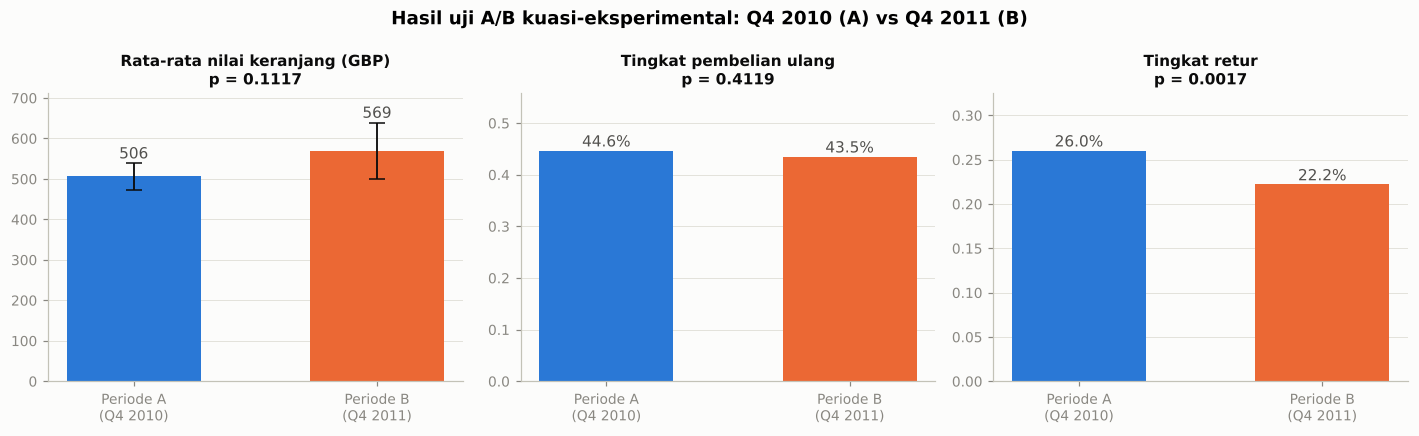

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metrics = [
    ("Rata-rata nilai keranjang (GBP)", [res.mean_a, res.mean_b], [[res.mean_a - 1.96 * A.std(ddof=1) / np.sqrt(len(A)), res.mean_b - 1.96 * B.std(ddof=1) / np.sqrt(len(B))], [res.mean_a + 1.96 * A.std(ddof=1) / np.sqrt(len(A)), res.mean_b + 1.96 * B.std(ddof=1) / np.sqrt(len(B))]], res.p_value, "{:,.0f}"),
    ("Tingkat pembelian ulang", [rep.rate_a, rep.rate_b], None, rep.p_value, "{:.1%}"),
    ("Tingkat retur", [ret.rate_a, ret.rate_b], None, ret.p_value, "{:.1%}"),
]
for ax, (title, vals, ci, p, fmt) in zip(axes, metrics):
    bars = ax.bar(["Periode A\n(Q4 2010)", "Periode B\n(Q4 2011)"], vals, color=[GROUP_COLORS["A"], GROUP_COLORS["B"]], width=0.55)
    if ci is not None:
        ax.errorbar([0, 1], vals, yerr=[np.array(vals) - np.array(ci[0]), np.array(ci[1]) - np.array(vals)], fmt="none", ecolor="#0b0b0b", capsize=5, linewidth=1.2)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.02 if ci is None else ci[1][int(bar.get_x() > 0)] * 1.02, fmt.format(v), ha="center", fontsize=10, color=INK_SECONDARY)
    ax.set_title(f"{title}\np = {p:.4f}", fontsize=10)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.grid(axis="x", visible=False)
fig.suptitle("Hasil uji A/B kuasi-eksperimental: Q4 2010 (A) vs Q4 2011 (B)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "ab_hasil.png")
plt.show()

## 7. Interpretasi bisnis

**Ringkasan hasil (angka dari sel-sel di atas)**

| Metrik | Periode A (Q4 2010) | Periode B (Q4 2011) | Selisih | Uji | p-value | Kesimpulan |
|---|---|---|---|---|---|---|
| Rata-rata nilai keranjang | GBP 506,11 (n = 5.793) | GBP 568,90 (n = 5.572) | +GBP 62,79 (+12,4%); IK 95% [-14,59; +140,17] | t Welch | 0,1117 | Tidak signifikan; Cohen's d = 0,03 (dapat diabaikan) |
| Tingkat pembelian ulang (pelanggan >= 2 invoice) | 44,6% | 43,5% | -1,1 poin; IK 95% [-3,9; +1,6] | chi-square | 0,4119 | Tidak signifikan |
| Tingkat retur (pelanggan >= 1 retur) | 26,0% | 22,2% | -3,7 poin; IK 95% [-6,1; -1,4] | chi-square | 0,0017 | **Signifikan**, retur turun |

**Bagaimana membaca hasil ini**

1. **Nilai keranjang**: rata-rata naik 12,4%, tetapi interval kepercayaan 95% mencakup nol dan Cohen's d hanya 0,03. Median kedua periode hampir identik (GBP 300,66 vs 302,94), jadi kenaikan rata-rata berasal dari segelintir pesanan grosir ekstrem (simpangan baku B dua kali lipat A). Uji pada skala log, yang lebih tahan pencilan, menunjukkan rasio geometrik 1,054 dengan p = 0,02 - ada indikasi keranjang "tipikal" sedikit lebih besar, tetapi secara praktis efeknya kecil. Analisis power menunjukkan uji ini hanya mampu mendeteksi perbedaan >= GBP 109 (d = 0,053) dengan power 80%; untuk efek sekecil yang diamati, power hanya 36%. Artinya: **tidak ada bukti perbedaan yang berarti secara bisnis**, bukan bukti tidak ada perbedaan sama sekali.
2. **Pembelian ulang**: stabil di sekitar 44% pada kedua periode. Loyalitas jangka pendek pelanggan grosir tidak berubah.
3. **Retur**: satu-satunya perubahan yang signifikan. Proporsi pelanggan yang melakukan retur turun dari 26,0% menjadi 22,2% (penurunan relatif 15%). Dalam eksperimen sungguhan ini akan menjadi sinyal keberhasilan (mis. perbaikan kemasan atau deskripsi produk); pada kuasi-eksperimen ini perlu dicek apakah ada perubahan kebijakan retur atau kualitas pengiriman antara 2010 dan 2011 sebelum diklaim sebagai hasil kampanye.
4. **Uji A/A** menghasilkan p = 0,95, memastikan prosedur tidak menghasilkan positif palsu.

**Rekomendasi**

- Jangan mengklaim "kampanye 2011 menaikkan nilai keranjang 12%" - angka itu tidak didukung uji statistik. Laporkan median dan interval kepercayaan, bukan hanya rata-rata.
- Tindak lanjuti penurunan tingkat retur: identifikasi perubahan operasional antara dua musim puncak (kemasan, kurir, deskripsi produk) karena potensi penghematannya nyata - nilai retur pada data ini mencapai GBP 716 ribu.
- Untuk pengambilan keputusan di masa depan, jalankan **eksperimen terkontrol**: acak pelanggan ke kelompok kontrol dan perlakuan *sebelum* kampanye, tentukan metrik utama dan ukuran sampel (berdasarkan efek minimum yang ingin dideteksi) di awal, lalu gunakan prosedur uji yang sama seperti di notebook ini.

**Keterbatasan**: tidak ada randomisasi; perbedaan antar periode bisa dipengaruhi pertumbuhan basis pelanggan, perubahan katalog, harga, dan kondisi ekonomi. Unit analisis invoice juga tidak sepenuhnya independen karena satu pelanggan bisa memiliki banyak invoice (korelasi intra-pelanggan membuat p-value sedikit terlalu optimis).